In [1]:
r"""
GeoSem-FSP : Uncertainty-aware Camera + LiDAR fusion autoencoder on PandaSet
-----------------------------------------------------------------------------
Single file for Kaggle.  Just paste into one notebook cell (or run as script).

Pipeline (matches the block diagram):
  Camera image (3xHxW)        LiDAR range image (6x64x512)
        |                               |
  Image encoder -> 64x32x32     LiDAR encoder -> 64x32x32
        |                               |
  Evidential head (alpha_C,p_C,u_C=K/S)   Evidential head (alpha_L,p_L,u_L=K/S)
        \______ Geometry-semantic uncertainty U_GS = sigmoid(w1(1-IoU)+w2 D_JS+w3 u_C+w4 u_L) ______/
                                    |
                  Uncertainty-aware fusion (+ U_GS bandwidth mask)
                                    |
                      Fused latent z (64x32x32) + U_GS map
                          /                         \
                 Image decoder                 LiDAR decoder
              (L1 + SSIM loss)             (masked L1 + BCE loss)

Settings requested:
  * dataset  : /kaggle/input/datasets/usharengaraju/pandaset-dataset
  * split    : 80% train / 10% val / 10% test   (split by SCENE -> no leakage)
  * input    : FRONT camera image + FRONT-view LiDAR range image
  * epochs   : 5
  * at the end: show reconstructed image and LiDAR

NEW - Scene understanding after fusion:
  Fused latent z (+ U_GS)  ->  Detection head  ->  per object:
      class (what is it), how many of each class, distance (m), lateral offset,
      direction (left/ahead/right), reliability (1 - U_GS).
  It also reports the nearest LiDAR return in the left / centre / right corridor.
  Object labels come from PandaSet cuboid annotations (annotations/cuboids/*.pkl.gz).

NEW - Camera-intrinsics based LiDAR mapping (v2):
  The LiDAR range image is now built with the camera pinhole model (intrinsics.json: fx, fy, cx, cy):
      u = fx*x/z + cx ,  v = fy*y/z + cy        (camera frame, native 1920x1080 pixels)
  Column of the range image = u / 1920 * 512, row = v / 1080 * 64. So LiDAR columns line up with
  camera columns (512 wide) and the 32x32 latent cell of both encoders sees the SAME image region.
  Detection labels (3D cuboids) use the same projection.

NEW - Loss follows the paper abstract:
  L = L_det + lam1*L_feat + lam2*L_geo-sem + lam3*L_comp   (+ lam_rec*L_rec, auxiliary)
    L_det      detection  : focal loss on class heatmap + L1 on (x,y,z,distance)
    L_feat     feature consistency between camera and LiDAR features, weighted by (1-U_GS)
    L_geo-sem  geometry-semantic agreement: evidential (Dirichlet) loss of both heads
               + (1 - IoU) geometric disagreement + Jensen-Shannon semantic conflict
    L_comp     compression fidelity: U_GS-driven quantisation error + rate (bits) term
    L_rec      image (L1+SSIM) and LiDAR (masked L1 + BCE) reconstruction, used to show recon.

NEW - YOLO + LiDAR (section 7):
  Pretrained YOLOv8 (COCO) detects objects on the camera image; the raw LiDAR points that
  fall inside each YOLO box give its real distance. The result is cross-checked against the
  fusion detection head. (Needs Internet ON in Kaggle once, to pip-install ultralytics and
  download yolov8n.pt.)
"""

'\nGeoSem-FSP : Uncertainty-aware Camera + LiDAR fusion autoencoder on PandaSet\n-----------------------------------------------------------------------------\nSingle file for Kaggle.  Just paste into one notebook cell (or run as script).\n\nPipeline (matches the block diagram):\n  Camera image (3xHxW)        LiDAR range image (6x64x512)\n        |                               |\n  Image encoder -> 64x32x32     LiDAR encoder -> 64x32x32\n        |                               |\n  Evidential head (alpha_C,p_C,u_C=K/S)   Evidential head (alpha_L,p_L,u_L=K/S)\n        \\______ Geometry-semantic uncertainty U_GS = sigmoid(w1(1-IoU)+w2 D_JS+w3 u_C+w4 u_L) ______/\n                                    |\n                  Uncertainty-aware fusion (+ U_GS bandwidth mask)\n                                    |\n                      Fused latent z (64x32x32) + U_GS map\n                          /                         \\\n                 Image decoder                 LiDAR decoder\n     

In [2]:
import os, glob, json, math, random, time, warnings
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
warnings.filterwarnings("ignore")

# ============================================================================
# 0. CONFIG
# ============================================================================

In [3]:
DATA_ROOT   = os.environ.get("DATA_ROOT", "/kaggle/input/datasets/usharengaraju/pandaset-dataset")
OUT_DIR     = "/kaggle/working"
EPOCHS      = int(os.environ.get("EPOCHS", 50))   # v3: 5 epochs is too few for sharp output; set 5 for a quick test
BATCH_SIZE  = 16
LR          = 1e-3
NUM_WORKERS = 4
SEED        = 42
FRAME_STRIDE = 1          # use every frame (set 2 or 4 to speed things up)

IMG_H, IMG_W = 256, 512   # camera input size
RV_H, RV_W   = 64, 512    # LiDAR range-image size (front view)
ORIG_W, ORIG_H = 1920, 1080   # native PandaSet camera size (fx, fy, cx, cy in intrinsics.json refer to this)
MAX_RANGE    = 80.0
K_CLASSES    = 8          # classes of the evidential heads
LATENT_C     = 64
GRID         = 32         # latent grid (32x32)
DET_H, DET_W = 64, 128    # v3: detection heatmap resolution (head upsamples the 32x32 latent x2 / x4)

DET_CLASSES  = ["Car", "Truck", "Bus", "Pedestrian", "TwoWheeler", "Obstacle"]
N_DET        = len(DET_CLASSES)
DET_THR      = 0.25       # score threshold when listing objects

# loss weights  L = L_det + lam1*L_feat + lam2*L_geo-sem + lam3*L_comp + lam_rec*L_rec
LAM_FEAT, LAM_GEOSEM, LAM_COMP, LAM_REC = 0.5, 0.5, 0.5, 1.0   # v3: lam2 0.2 -> 0.5 (heads learn U_GS better)
RATE_W       = 0.01       # weight of the bit-rate term inside L_comp
Q_MIN, Q_MAX = 0.01, 0.20 # quantiser step: high U_GS -> Q_MIN (fine), low U_GS -> Q_MAX (coarse)  (v3: finer)

# ---- v3 settings (sharper reconstruction, better uncertainty, better detection) ----
MASK_MIN     = 0.75       # bandwidth mask keeps at least 75% of latent channels (was 50%)
KL_MAX       = 0.05       # final weight of the evidential KL term (was 1.0 -> evidence stayed ~0, U_GS flat)
LAM_GRAD     = 1.0        # weight of the edge (gradient) loss on the image
LIDAR_GRAD_W = 0.5        # weight of the edge loss on the LiDAR range image
DET_THR_CLS  = {"Car": 0.35, "Truck": 0.35, "Bus": 0.35, "Pedestrian": 0.30, "TwoWheeler": 0.30, "Obstacle": 0.45}

USE_YOLO     = True                                   # YOLO + LiDAR section at the end
YOLO_WEIGHTS = os.environ.get("YOLO_WEIGHTS", "yolov8n.pt")   # or yolov8s.pt / yolov8m.pt / your own .pt
YOLO_CONF    = 0.25
# COCO ids: person, bicycle, car, motorcycle, bus, truck, traffic light, stop sign
YOLO_CLASSES = [0, 1, 2, 3, 5, 7, 9, 11]
YOLO_TO_DET  = {"person": "Pedestrian", "bicycle": "TwoWheeler", "motorcycle": "TwoWheeler",
                "car": "Car", "bus": "Bus", "truck": "Truck"}

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)


Device: cuda


# ============================================================================
# 1. DATA : discover scenes, 80/10/10 split, dataset class
# ============================================================================

In [4]:
def find_scenes(root):
    """A scene = folder that contains camera/front_camera and lidar."""
    scenes = []
    for cam_dir in glob.glob(os.path.join(root, "**", "camera", "front_camera"), recursive=True):
        scene = os.path.dirname(os.path.dirname(cam_dir))
        if os.path.isdir(os.path.join(scene, "lidar")) and \
           os.path.isfile(os.path.join(cam_dir, "poses.json")):
            scenes.append(scene)
    return sorted(set(scenes))


def quat_to_rot(w, x, y, z):
    return np.array([
        [1 - 2 * (y * y + z * z), 2 * (x * y - z * w),     2 * (x * z + y * w)],
        [2 * (x * y + z * w),     1 - 2 * (x * x + z * z), 2 * (y * z - x * w)],
        [2 * (x * z - y * w),     2 * (y * z + x * w),     1 - 2 * (x * x + y * y)],
    ])


def pose_to_world2cam(p):
    """PandaSet camera pose (camera->world) -> world->camera 4x4 matrix."""
    h, t = p["heading"], p["position"]
    R = quat_to_rot(h["w"], h["x"], h["y"], h["z"])
    M = np.eye(4); M[:3, :3] = R; M[:3, 3] = [t["x"], t["y"], t["z"]]
    return np.linalg.inv(M)


def _stem_index(path):
    """'00.pkl.gz' / '000.jpg' / '12.pkl' -> int index (None if not numeric)."""
    stem = os.path.basename(path).split(".")[0]
    return int(stem) if stem.isdigit() else None


def map_label(name):
    """PandaSet label string -> detection class id (or -1 to ignore)."""
    n = str(name).lower()
    if "pedestrian" in n:                                        return 3
    if "bicycle" in n or "motorcycle" in n:                      return 4
    if "bus" in n or "tram" in n or "train" in n:                return 2
    if "pickup" in n:                                            return 0
    if "truck" in n:                                             return 1
    if any(k in n for k in ("car", "vehicle", "van", "towed")):  return 0
    if any(k in n for k in ("cone", "pylon", "barrier", "sign", "container", "animal")): return 5
    return -1


def build_samples(scene_list):
    samples = []
    for sc in scene_list:
        cam_dir = os.path.join(sc, "camera", "front_camera")
        with open(os.path.join(cam_dir, "poses.json")) as f:
            poses = json.load(f)
        if isinstance(poses, dict):
            poses = [poses[k] for k in sorted(poses, key=lambda k: int(k))]
        try:
            with open(os.path.join(cam_dir, "intrinsics.json")) as f:
                it = json.load(f); K = (it["fx"], it["fy"], it["cx"], it["cy"])
        except Exception:
            K = (1970.0, 1970.0, 970.0, 483.0)

        def index_files(folder, exts, pred=None):
            d = {}
            for fp in glob.glob(os.path.join(folder, "*")):
                if fp.endswith(exts):
                    i = _stem_index(fp)
                    if i is not None: d[i] = fp
            return d
        cams = index_files(cam_dir, (".jpg", ".jpeg", ".png"))
        lids = index_files(os.path.join(sc, "lidar"), (".pkl.gz", ".pkl", ".gz"))
        anns = index_files(os.path.join(sc, "annotations", "cuboids"), (".pkl.gz", ".pkl", ".gz"))

        for idx in sorted(set(cams) & set(lids))[::FRAME_STRIDE]:
            if idx < len(poses):
                samples.append(dict(img=cams[idx], lid=lids[idx], ann=anns.get(idx),
                                    w2c=pose_to_world2cam(poses[idx]).astype(np.float64), K=K))
    return samples


def project_to_pixels(pc, K):
    """Camera-frame points (x right, y down, z forward) -> native pixel coords with the pinhole model."""
    fx, fy, cx, cy = K
    u = fx * pc[:, 0] / pc[:, 2] + cx
    v = fy * pc[:, 1] / pc[:, 2] + cy
    return u, v


def lidar_to_front_range_image(lidar_path, w2c, K):
    """World-frame LiDAR points -> camera frame -> pixel-aligned (6,64,512) range image.
       Uses the camera INTRINSICS: u = fx*x/z+cx, v = fy*y/z+cy.
       column = u/1920*512 (same columns as the resized camera image), row = v/1080*64.
       Channels: range, x, y, z, intensity, valid-mask  (all normalised)."""
    df = pd.read_pickle(lidar_path)
    if "d" in df.columns:                       # d==0 : 360 deg mechanical LiDAR (64 beams)
        df = df[df["d"] == 0]
    pts = df[["x", "y", "z"]].to_numpy(np.float64)
    inten = df["i"].to_numpy(np.float32) if "i" in df.columns else np.zeros(len(df), np.float32)

    pc = pts @ w2c[:3, :3].T + w2c[:3, 3]       # camera frame: x right, y down, z forward
    ok = pc[:, 2] > 1.0                         # in front of the camera
    pc, inten = pc[ok], inten[ok]
    u, v = project_to_pixels(pc, K)
    r = np.linalg.norm(pc, axis=1)
    keep = (u >= 0) & (u < ORIG_W) & (v >= 0) & (v < ORIG_H) & (r < MAX_RANGE) & (r > 1.0)   # inside camera FOV
    pc, u, v, r, inten = pc[keep], u[keep], v[keep], r[keep], inten[keep]

    col = np.clip((u / ORIG_W * RV_W).astype(np.int64), 0, RV_W - 1)
    row = np.clip((v / ORIG_H * RV_H).astype(np.int64), 0, RV_H - 1)

    order = np.argsort(-r)                      # far -> near, so nearest point is written last
    row, col = row[order], col[order]
    img = np.zeros((6, RV_H, RV_W), np.float32)
    img[0, row, col] = (r[order] / MAX_RANGE)
    img[1, row, col] = np.clip(pc[order, 0] / 40.0, -1, 1)
    img[2, row, col] = np.clip(pc[order, 1] / 10.0, -1, 1)
    img[3, row, col] = (pc[order, 2] / MAX_RANGE)
    img[4, row, col] = np.clip(inten[order] / 255.0, 0, 1)
    img[5, row, col] = 1.0
    return img


def build_det_targets(ann_path, w2c, K):
    """3D cuboids (world) -> CenterNet-style targets on the 32x32 latent grid
       (cell = centre projected into the image with the camera intrinsics).
       hm  : (N_DET,DET_H,DET_W) gaussian heatmap, 1.0 at object centres
       reg : (4,DET_H,DET_W)     [x/40, y/10, z/80, dist/80] in camera frame at centre cells
       rm  : (1,DET_H,DET_W)     1 where reg is valid"""
    hm  = np.zeros((N_DET, DET_H, DET_W), np.float32)
    reg = np.zeros((4, DET_H, DET_W), np.float32)
    rm  = np.zeros((1, DET_H, DET_W), np.float32)
    if ann_path is None:
        return hm, reg, rm
    df = pd.read_pickle(ann_path)
    if len(df) == 0 or "position.x" not in df.columns:
        return hm, reg, rm
    pos = df[["position.x", "position.y", "position.z"]].to_numpy(np.float64)
    labels = df["label"].tolist()
    pc = pos @ w2c[:3, :3].T + w2c[:3, 3]
    dist_all = np.linalg.norm(pc, axis=1)
    fx, fy, cx0, cy0 = K
    for k in np.argsort(-dist_all):                       # far -> near (near wins)
        c = map_label(labels[k])
        x, y, z = pc[k]; d = dist_all[k]
        if c < 0 or z <= 1.0 or d > MAX_RANGE: continue
        u, v = fx * x / z + cx0, fy * y / z + cy0         # intrinsics: centre -> pixel
        if not (0 <= u < ORIG_W and 0 <= v < ORIG_H): continue
        cx = int(np.clip(u / ORIG_W * DET_W, 0, DET_W - 1))
        cy = int(np.clip(v / ORIG_H * DET_H, 0, DET_H - 1))
        for dy in range(-3, 4):
            for dx in range(-3, 4):
                yy, xx = cy + dy, cx + dx
                if 0 <= yy < DET_H and 0 <= xx < DET_W:
                    hm[c, yy, xx] = max(hm[c, yy, xx], math.exp(-(dx * dx + dy * dy) / (2 * 1.5 ** 2)))
        hm[c, cy, cx] = 1.0
        reg[:, cy, cx] = [x / 40.0, y / 10.0, z / 80.0, d / 80.0]
        rm[0, cy, cx] = 1.0
    return hm, reg, rm


class PandaFrontDataset(Dataset):
    def __init__(self, samples):
        self.samples = samples

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, i):
        s = self.samples[i]
        im = Image.open(s["img"]); im.draft("RGB", (960, 540))
        im = im.convert("RGB").resize((IMG_W, IMG_H), Image.BILINEAR)
        im = torch.from_numpy(np.asarray(im, np.float32) / 255.0).permute(2, 0, 1)
        rv = torch.from_numpy(lidar_to_front_range_image(s["lid"], s["w2c"], s["K"]))
        hm, reg, rm = build_det_targets(s["ann"], s["w2c"], s["K"])
        tgt = dict(hm=torch.from_numpy(hm), reg=torch.from_numpy(reg), rm=torch.from_numpy(rm))
        return im, rv, tgt


scenes = find_scenes(DATA_ROOT)
print(f"Found {len(scenes)} scenes under {DATA_ROOT}")
assert len(scenes) > 0, "No scenes found - check DATA_ROOT / folder structure (print os.listdir)."

rng = random.Random(SEED); rng.shuffle(scenes)
n = len(scenes)
n_tr, n_va = int(round(0.8 * n)), int(round(0.1 * n))
train_sc, val_sc, test_sc = scenes[:n_tr], scenes[n_tr:n_tr + n_va], scenes[n_tr + n_va:]
print(f"Scenes -> train {len(train_sc)} | val {len(val_sc)} | test {len(test_sc)}")

train_samples, val_samples, test_samples = map(build_samples, (train_sc, val_sc, test_sc))
print(f"Frames -> train {len(train_samples)} | val {len(val_samples)} | test {len(test_samples)}")

if len(train_samples) == 0:
    sc = train_sc[0]
    print("\nNo frames matched. Debug info for first scene:", sc)
    for sub in ("camera/front_camera", "lidar"):
        d = os.path.join(sc, *sub.split("/"))
        print(f"  {sub}:", sorted(os.listdir(d))[:8] if os.path.isdir(d) else "MISSING")
    raise RuntimeError("0 training frames - send the debug listing above so the file matching can be adjusted.")

train_ds, val_ds, test_ds = map(PandaFrontDataset, (train_samples, val_samples, test_samples))
mk = lambda ds, sh: DataLoader(ds, batch_size=BATCH_SIZE, shuffle=sh, num_workers=NUM_WORKERS,
                               pin_memory=True, drop_last=sh, persistent_workers=NUM_WORKERS > 0)
train_dl, val_dl, test_dl = mk(train_ds, True), mk(val_ds, False), mk(test_ds, False)

# quick sanity checks: LiDAR projection coverage + annotation availability
probe = [val_ds[i] for i in range(0, len(val_ds), max(1, len(val_ds) // 5))]
cov = np.mean([p[1][5].mean().item() for p in probe])
print(f"LiDAR front-view pixel coverage: {cov * 100:.1f}%  (expected roughly 5-40%)")
if cov < 0.01:
    print("WARNING: very low coverage - camera pose / intrinsics convention may differ in this copy of the dataset.")

ann_frac = np.mean([s["ann"] is not None for s in train_samples])
objs_per_frame = np.mean([p[2]["rm"].sum().item() for p in probe])
USE_DET = ann_frac > 0.5 and objs_per_frame > 0
print(f"Cuboid annotations found for {ann_frac * 100:.0f}% of train frames; "
      f"avg labelled objects in front view: {objs_per_frame:.1f}")
if not USE_DET:
    print("NOTE: no usable cuboid annotations -> object-detection head is NOT trained. "
          "Only the LiDAR corridor-distance report will be produced.")


Found 39 scenes under /kaggle/input/datasets/usharengaraju/pandaset-dataset
Scenes -> train 31 | val 4 | test 4
Frames -> train 2480 | val 320 | test 320
LiDAR front-view pixel coverage: 28.7%  (expected roughly 5-40%)
Cuboid annotations found for 100% of train frames; avg labelled objects in front view: 26.4


# ============================================================================
# 2. MODEL
# ============================================================================

In [5]:
# ----------------------------------------------------------------------------
# 1. Basic block:  Conv3x3 -> BatchNorm -> ReLU          (unchanged)
# ----------------------------------------------------------------------------
def cbr(i, o, s=(1, 1)):
    return nn.Sequential(nn.Conv2d(i, o, 3, s, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))


# ----------------------------------------------------------------------------
# 2. PixelShuffle / PixelUnshuffle with DIFFERENT factors for height and width
#    (nn.PixelShuffle only allows one square factor, but our LiDAR image needs
#     e.g. x1 in height and x2 in width)
# ----------------------------------------------------------------------------
class PixelShuffle2d(nn.Module):
    """Depth -> space:  (B, C*rh*rw, H, W)  ->  (B, C, H*rh, W*rw)

    Every group of rh*rw channels is spread into a rh x rw block of pixels.
    If rh == rw this is exactly nn.PixelShuffle(r).
    """
    def __init__(self, rh, rw):
        super().__init__()
        self.rh, self.rw = rh, rw

    def forward(self, x):
        B, C_in, H, W = x.shape
        rh, rw = self.rh, self.rw
        C = C_in // (rh * rw)
        x = x.reshape(B, C, rh, rw, H, W)        # split the channel axis into (C, rh, rw)
        x = x.permute(0, 1, 4, 2, 5, 3)          # -> (B, C, H, rh, W, rw)
        return x.reshape(B, C, H * rh, W * rw)   # merge (H, rh) and (W, rw)


class PixelUnshuffle2d(nn.Module):
    """Space -> depth (exact inverse of PixelShuffle2d):  (B, C, H*rh, W*rw) -> (B, C*rh*rw, H, W)"""
    def __init__(self, rh, rw):
        super().__init__()
        self.rh, self.rw = rh, rw

    def forward(self, x):
        B, C, H_big, W_big = x.shape
        rh, rw = self.rh, self.rw
        H, W = H_big // rh, W_big // rw
        x = x.reshape(B, C, H, rh, W, rw)        # split the pixel axes
        x = x.permute(0, 1, 3, 5, 2, 4)          # -> (B, C, rh, rw, H, W)
        return x.reshape(B, C * rh * rw, H, W)   # move the rh x rw block into channels


def icnr_(conv, rh, rw):
    """ICNR initialisation: at the start, PixelShuffle behaves like nearest-neighbour upsampling.
    This removes the 'checkerboard' pattern that sub-pixel convolution can show early in training."""
    out_ch, in_ch, kh, kw = conv.weight.shape
    base = torch.empty(out_ch // (rh * rw), in_ch, kh, kw)
    nn.init.kaiming_normal_(base)
    # the rh*rw channels that become one output channel share the same kernel at the start
    conv.weight.data.copy_(base.repeat_interleave(rh * rw, dim=0))


# ----------------------------------------------------------------------------
# 3. ENCODER  (downsampling)
# ----------------------------------------------------------------------------
class ResBlock(nn.Module):
    """Residual block:  x + (Conv-BN-ReLU-Conv-BN)(x), then ReLU.  Keeps fine detail flowing through the network."""
    def __init__(self, ch):
        super().__init__()
        self.body = nn.Sequential(nn.Conv2d(ch, ch, 3, 1, 1, bias=False), nn.BatchNorm2d(ch), nn.ReLU(inplace=True),
                                  nn.Conv2d(ch, ch, 3, 1, 1, bias=False), nn.BatchNorm2d(ch))
        self.act = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.act(x + self.body(x))


class DownBlock(nn.Module):
    """Make the feature map smaller by `stride` = (sh, sw).

    mode = "conv"      : Conv3x3 with stride                      (default, same as before)
    mode = "unshuffle" : PixelUnshuffle (space->depth) + Conv3x3  (no information is thrown away
                         by the downsampling itself; the conv decides what to keep)
    """
    def __init__(self, in_ch, out_ch, stride, mode="conv"):
        super().__init__()
        sh, sw = stride
        if mode == "unshuffle" and (sh, sw) != (1, 1):
            self.body = nn.Sequential(PixelUnshuffle2d(sh, sw), cbr(in_ch * sh * sw, out_ch))
        else:
            self.body = cbr(in_ch, out_ch, stride)

    def forward(self, x):
        return self.body(x)


class Encoder(nn.Module):
    """4 stages.  Each stage = DownBlock (stride) + ResBlock.  (v3: wider: 64-128-128-LATENT_C)"""
    def __init__(self, in_ch, strides, down="conv"):
        super().__init__()
        chs = [in_ch, 64, 128, 128, LATENT_C]
        layers = []
        for i, s in enumerate(strides):
            layers += [DownBlock(chs[i], chs[i + 1], s, down),   # smaller map
                       ResBlock(chs[i + 1])]                     # refine (residual)
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


# ----------------------------------------------------------------------------
# 4. DECODER  (upsampling with PixelShuffle = learned inverse of the encoder)
# ----------------------------------------------------------------------------
class UpBlock(nn.Module):
    """Make the feature map bigger by `scale` = (rh, rw)  using sub-pixel convolution:

        (B, in_ch,  H,    W   )
          -> Conv3x3 to out_ch*rh*rw channels      (the network "predicts" the rh x rw sub-pixels)
          -> PixelShuffle2d                        (B, out_ch, H*rh, W*rw)
          -> BatchNorm -> ReLU
    """
    def __init__(self, in_ch, out_ch, scale):
        super().__init__()
        rh, rw = scale
        self.conv = nn.Conv2d(in_ch, out_ch * rh * rw, 3, 1, 1, bias=False)
        icnr_(self.conv, rh, rw)
        self.shuffle = PixelShuffle2d(rh, rw)
        self.bn = nn.BatchNorm2d(out_ch)
        self.act = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.act(self.bn(self.shuffle(self.conv(x))))


class Decoder(nn.Module):
    """4 stages.  Each stage = UpBlock (bigger map) + ResBlock.  Last layer: 3x3 conv to out_ch.  (v3: wider)"""
    def __init__(self, out_ch, scales):
        super().__init__()
        chs = [LATENT_C, 128, 128, 64, 64]
        layers = []
        for i, sc in enumerate(scales):
            layers += [UpBlock(chs[i], chs[i + 1], sc),          # bigger map (PixelShuffle)
                       ResBlock(chs[i + 1])]                     # refine (residual)
        layers += [nn.Conv2d(chs[-1], out_ch, 3, 1, 1)]
        self.net = nn.Sequential(*layers)

    def forward(self, z):
        return self.net(z)


# ----------------------------------------------------------------------------
# 5. Optional quick test  ->  run  _shape_check()  once in a cell
# ----------------------------------------------------------------------------
def _shape_check():
    # PixelShuffle2d must be the exact inverse of PixelUnshuffle2d, and equal nn.PixelShuffle for square factors
    t = torch.randn(2, 8, 5, 7)
    assert torch.equal(PixelUnshuffle2d(2, 2)(PixelShuffle2d(2, 2)(t)), t)
    assert torch.equal(PixelShuffle2d(2, 2)(t), nn.PixelShuffle(2)(t))
    t = torch.randn(2, 6, 5, 7)
    assert torch.equal(PixelUnshuffle2d(1, 3)(PixelShuffle2d(1, 3)(t)), t)

    for down in ("conv", "unshuffle"):
        img = torch.randn(2, 3, 256, 512)
        rv = torch.randn(2, 6, 64, 512)
        zi = Encoder(3, [(2, 2), (2, 2), (2, 2), (1, 2)], down)(img)
        zl = Encoder(6, [(1, 2), (1, 2), (2, 2), (1, 2)], down)(rv)
        assert zi.shape == zl.shape == (2, LATENT_C, 32, 32), (zi.shape, zl.shape)
    assert Decoder(3, [(1, 2), (2, 2), (2, 2), (2, 2)])(zi).shape == (2, 3, 256, 512)
    assert Decoder(2, [(1, 2), (2, 2), (1, 2), (1, 2)])(zl).shape == (2, 2, 64, 512)
    hm, reg = DetectionHead()(torch.randn(2, LATENT_C, 32, 32), torch.rand(2, 1, 32, 32))
    assert hm.shape == (2, N_DET, DET_H, DET_W) and reg.shape == (2, 4, DET_H, DET_W), (hm.shape, reg.shape)
    print("shape check OK")


class EvidentialHead(nn.Module):
    """features -> Dirichlet params alpha = softplus(logits)+1, p = alpha/S, u = K/S"""
    def __init__(self, K=K_CLASSES):
        super().__init__()
        self.K = K
        self.net = nn.Sequential(cbr(LATENT_C, LATENT_C), nn.Conv2d(LATENT_C, K, 1))

    def forward(self, f):
        evidence = F.softplus(self.net(f))
        alpha = evidence + 1.0
        S = alpha.sum(1, keepdim=True)
        return alpha, alpha / S, self.K / S


class GeoSemUncertainty(nn.Module):
    """U_GS = sigmoid(w1(1-IoU) + w2 D_JS + w3 u_C + w4 u_L + b)   (w learnable)"""
    def __init__(self):
        super().__init__()
        self.w = nn.Parameter(torch.ones(4))
        self.b = nn.Parameter(torch.tensor(-1.5))

    @staticmethod
    def js_div(p, q, eps=1e-8):
        m = 0.5 * (p + q)
        kl = lambda a, b: (a * (torch.log(a + eps) - torch.log(b + eps))).sum(1, keepdim=True)
        return (0.5 * kl(p, m) + 0.5 * kl(q, m)) / math.log(2.0)     # in [0,1]

    def forward(self, pC, pL, uC, uL):
        pC, pL, uC, uL = pC.detach(), pL.detach(), uC.detach(), uL.detach()
        occC, occL = 1 - pC[:, :1], 1 - pL[:, :1]                     # class 0 = "empty"
        iou = occC * occL / (occC + occL - occC * occL + 1e-6)        # soft IoU of occupancy
        djs = self.js_div(pC, pL)
        s = self.w[0] * (1 - iou) + self.w[1] * djs + self.w[2] * uC + self.w[3] * uL + self.b
        return torch.sigmoid(s)


class UncertaintyAwareFusion(nn.Module):
    """Confidence-weighted feature mixing + U_GS-controlled channel bandwidth mask."""
    def __init__(self):
        super().__init__()
        self.proj = nn.Sequential(nn.Conv2d(2 * LATENT_C, LATENT_C, 1, bias=False),
                                  nn.BatchNorm2d(LATENT_C), nn.ReLU(inplace=True),
                                  nn.Conv2d(LATENT_C, LATENT_C, 3, 1, 1))     # v3: linear output (no ReLU) -> z can be +/-
        self.register_buffer("ch", (torch.arange(LATENT_C).float() / LATENT_C).view(1, -1, 1, 1))

    def forward(self, fC, fL, uC, uL, U):
        aC, aL = 1 - uC, 1 - uL
        norm = aC + aL + 1e-6
        fused = self.proj(torch.cat([fC * (2 * aC / norm), fL * (2 * aL / norm)], 1))
        bw = MASK_MIN + (1.0 - MASK_MIN) * U               # more uncertain -> more channels kept (>= MASK_MIN)
        mask = torch.sigmoid(12.0 * (bw - self.ch))         # soft bandwidth mask over channels
        return fused * mask


class SpatialAwareCompressor(nn.Module):
    """On-vehicle compression of the fused latent. The quantiser step depends on U_GS:
       high U_GS (cross-modal conflict) -> small step -> high fidelity,
       low  U_GS (consistent regions)   -> large step -> heavy compression.
       Straight-through rounding keeps it trainable. `bits` is a rate proxy (bits / element)."""
    def forward(self, z, U):
        step = Q_MIN + (Q_MAX - Q_MIN) * (1.0 - U.detach())
        q = torch.round(z / step)
        z_hat = z + (q * step - z).detach()                 # decompressed latent at the remote unit
        bits = torch.log2(1.0 + torch.abs(z) / step)
        return z_hat, bits


class DetectionHead(nn.Module):
    """Scene-understanding head on the decompressed latent z_hat (+ U_GS map).   (v3: higher resolution)
       z_hat (64x32x32) --UpBlock x(2,4)--> 64x128 map --ResBlock--> heads
       hm_logit : class heatmap on a DET_H x DET_W grid   (what is it)
       reg      : [x, y, z, distance] in the camera frame  (where / how far)"""
    def __init__(self):
        super().__init__()
        self.up = UpBlock(LATENT_C, 96, (DET_H // GRID, DET_W // GRID))        # 32x32 -> 64x128
        self.trunk = nn.Sequential(cbr(96 + 1, 96), ResBlock(96), cbr(96, 64))
        self.hm = nn.Conv2d(64, N_DET, 1)
        self.reg = nn.Conv2d(64, 4, 1)
        nn.init.constant_(self.hm.bias, -2.19)

    def forward(self, z, U):
        h = self.up(z)
        U_up = F.interpolate(U, size=h.shape[-2:], mode="bilinear", align_corners=False)
        h = self.trunk(torch.cat([h, U_up], 1))
        return self.hm(h), self.reg(h)


class GeoSemFSP(nn.Module):
    def __init__(self):
        super().__init__()
        self.img_enc = Encoder(3, [(2, 2), (2, 2), (2, 2), (1, 2)])      # 256x512 -> 32x32
        self.lid_enc = Encoder(6, [(1, 2), (1, 2), (2, 2), (1, 2)])      # 64x512  -> 32x32
        self.head_c, self.head_l = EvidentialHead(), EvidentialHead()
        self.unc = GeoSemUncertainty()
        self.fusion = UncertaintyAwareFusion()
        self.img_dec = Decoder(3, [(1, 2), (2, 2), (2, 2), (2, 2)])      # 32x32 -> 256x512
        self.lid_dec = Decoder(2, [(1, 2), (2, 2), (1, 2), (1, 2)])      # 32x32 -> 64x512 (anisotropic)
        self.compress = SpatialAwareCompressor()                         # vehicle -> remote unit
        self.det_head = DetectionHead()                                  # objects / distance

    def forward(self, img, rv):
        fC, fL = self.img_enc(img), self.lid_enc(rv)
        aC, pC, uC = self.head_c(fC)
        aL, pL, uL = self.head_l(fL)
        U = self.unc(pC, pL, uC, uL)
        z = self.fusion(fC, fL, uC, uL, U)                  # fused latent (vehicle side)
        z_hat, bits = self.compress(z, U)                   # compressed -> transmitted -> decompressed
        img_rec = torch.sigmoid(self.img_dec(z_hat))        # everything below runs at the remote unit
        lo = self.lid_dec(z_hat)
        hm_logit, reg = self.det_head(z_hat, U)
        return dict(hm_logit=hm_logit, reg=reg, img=img_rec, range=torch.sigmoid(lo[:, :1]), mask_logit=lo[:, 1:],
                    aC=aC, aL=aL, pC=pC, pL=pL, uC=uC, uL=uL, U=U, z=z, z_hat=z_hat, bits=bits, fC=fC, fL=fL)


# ============================================================================
# 3. LOSSES
# ============================================================================

In [6]:
def ssim(x, y, C1=0.01 ** 2, C2=0.03 ** 2):
    mx, my = F.avg_pool2d(x, 7, 1, 3), F.avg_pool2d(y, 7, 1, 3)
    sx = F.avg_pool2d(x * x, 7, 1, 3) - mx ** 2
    sy = F.avg_pool2d(y * y, 7, 1, 3) - my ** 2
    sxy = F.avg_pool2d(x * y, 7, 1, 3) - mx * my
    s = ((2 * mx * my + C1) * (2 * sxy + C2)) / ((mx ** 2 + my ** 2 + C1) * (sx + sy + C2))
    return s.mean()


def gradient_loss(pred, gt):
    """Edge loss: L1 between horizontal / vertical image gradients -> keeps edges sharp (fights blur)."""
    dx = lambda t: t[:, :, :, 1:] - t[:, :, :, :-1]
    dy = lambda t: t[:, :, 1:, :] - t[:, :, :-1, :]
    return F.l1_loss(dx(pred), dx(gt)) + F.l1_loss(dy(pred), dy(gt))


def image_loss(pred, gt):
    return F.l1_loss(pred, gt) + (1 - ssim(pred, gt)) + LAM_GRAD * gradient_loss(pred, gt)   # L1 + SSIM + edge


def lidar_loss(out, rv):
    """Masked L1 (range) + masked edge loss + BCE + Dice (mask).  Dice fixes the mask imbalance (few valid pixels)."""
    r_p, r_g, m = out["range"], rv[:, 0:1], rv[:, 5:6]
    l1 = (torch.abs(r_p - r_g) * m).sum() / (m.sum() + 1e-6)                    # masked L1
    mx, my = m[:, :, :, 1:] * m[:, :, :, :-1], m[:, :, 1:, :] * m[:, :, :-1, :]  # both neighbours valid
    gx = (torch.abs((r_p[:, :, :, 1:] - r_p[:, :, :, :-1]) - (r_g[:, :, :, 1:] - r_g[:, :, :, :-1])) * mx).sum() / (mx.sum() + 1e-6)
    gy = (torch.abs((r_p[:, :, 1:, :] - r_p[:, :, :-1, :]) - (r_g[:, :, 1:, :] - r_g[:, :, :-1, :])) * my).sum() / (my.sum() + 1e-6)
    bce = F.binary_cross_entropy_with_logits(out["mask_logit"], m)             # BCE
    p = torch.sigmoid(out["mask_logit"])
    dice = 1 - (2 * (p * m).sum() + 1) / (p.sum() + m.sum() + 1)
    return l1 + LIDAR_GRAD_W * (gx + gy) + bce + dice


def pseudo_classes(rv, size=(32, 32)):
    """Self-supervised labels for the evidential heads (no semantic labels needed):
       class 0 = empty, classes 1..7 = coarse range bins of the LiDAR geometry."""
    m, r = rv[:, 5:6], rv[:, 0:1] * rv[:, 5:6]
    occ = F.adaptive_avg_pool2d(m, size)
    mean_r = F.adaptive_avg_pool2d(r, size) / (occ + 1e-6)
    bounds = torch.tensor([0.08, 0.15, 0.25, 0.35, 0.5, 0.7], device=rv.device)
    cls = torch.bucketize(mean_r.contiguous(), bounds) + 1
    cls = torch.where(occ < 0.05, torch.zeros_like(cls), cls)
    return cls.squeeze(1).long()


def kl_dirichlet(alpha, K=K_CLASSES):
    S = alpha.sum(1, keepdim=True)
    return (torch.lgamma(S) - math.lgamma(K) - torch.lgamma(alpha).sum(1, keepdim=True)
            + ((alpha - 1) * (torch.digamma(alpha) - torch.digamma(S))).sum(1, keepdim=True))


def evidential_loss(alpha, target, kl_w):
    y = F.one_hot(target, K_CLASSES).permute(0, 3, 1, 2).float()
    S = alpha.sum(1, keepdim=True)
    p = alpha / S
    mse = ((y - p) ** 2).sum(1) + (p * (1 - p) / (S + 1)).sum(1)
    alpha_t = y + (1 - y) * alpha
    return mse.mean() + kl_w * kl_dirichlet(alpha_t).mean()


def detection_loss(out, tgt):
    """CenterNet focal loss on the heatmap + L1 on [x,y,z,dist] at object centres."""
    pred = torch.sigmoid(out["hm_logit"]).clamp(1e-4, 1 - 1e-4)
    gt = tgt["hm"]
    pos = gt.eq(1).float()
    pos_l = (torch.log(pred) * (1 - pred) ** 2 * pos).sum()
    neg_l = (torch.log(1 - pred) * pred ** 2 * (1 - gt) ** 4 * (1 - pos)).sum()
    focal = -(pos_l + neg_l) / pos.sum().clamp(min=1.0)
    rm = tgt["rm"]
    reg = (torch.abs(out["reg"] - tgt["reg"]) * rm).sum() / (rm.sum() * 4 + 1e-6)
    return focal + 5.0 * reg


def soft_iou(pC, pL):
    """Soft IoU of camera vs LiDAR occupancy (class 0 = empty)."""
    a, b = 1 - pC[:, :1], 1 - pL[:, :1]
    return a * b / (a + b - a * b + 1e-6)


def feature_consistency_loss(out):
    """L_feat: camera and LiDAR features should agree where the modalities are consistent
       (weight 1 - U_GS), so conflicting regions are not forced together."""
    cos = F.cosine_similarity(out["fC"], out["fL"], dim=1, eps=1e-6).unsqueeze(1)
    w = (1 - out["U"]).detach()
    return (w * (1 - cos)).sum() / (w.sum() + 1e-6)


def geo_sem_loss(out, rv, kl_w):
    """L_geo-sem: evidential loss of both heads + geometric (1-IoU) and semantic (JS) agreement."""
    pc = pseudo_classes(rv)
    evid = evidential_loss(out["aC"], pc, kl_w) + evidential_loss(out["aL"], pc, kl_w)
    agree = (1 - soft_iou(out["pC"], out["pL"])).mean() + GeoSemUncertainty.js_div(out["pC"], out["pL"]).mean()
    return evid + 0.5 * agree


def compression_loss(out):
    """L_comp: fidelity of the decompressed latent (errors in high-U_GS regions cost more)
       + rate term (estimated bits per latent element)."""
    w = 0.5 + out["U"].detach()
    fid = (w * (out["z"] - out["z_hat"].detach()) ** 2).mean()      # pulls z onto its quantisation grid
    rate = out["bits"].mean()
    return fid + RATE_W * rate, rate


def total_loss(out, img, rv, tgt, kl_w):
    """L = L_det + lam1*L_feat + lam2*L_geo-sem + lam3*L_comp  (+ lam_rec*L_rec)"""
    zero = torch.zeros((), device=img.device)
    l_det = detection_loss(out, tgt) if USE_DET else zero
    l_feat = feature_consistency_loss(out)
    l_gs = geo_sem_loss(out, rv, kl_w)
    l_comp, bits = compression_loss(out)
    rec_i, rec_l = image_loss(out["img"], img), lidar_loss(out, rv)
    loss = l_det + LAM_FEAT * l_feat + LAM_GEOSEM * l_gs + LAM_COMP * l_comp + LAM_REC * (rec_i + rec_l)
    comps = dict(det=l_det, feat=l_feat, geosem=l_gs, comp=l_comp, bits=bits, img=rec_i, lid=rec_l)
    return loss, comps


In [7]:
# ---- v3: quick smoke test (2 seconds). Runs the whole model + loss + backward on random data BEFORE training ----
def _smoke_test():
    _m = GeoSemFSP().to(DEVICE)
    _img = torch.rand(2, 3, IMG_H, IMG_W, device=DEVICE)
    _rv = torch.rand(2, 6, RV_H, RV_W, device=DEVICE); _rv[:, 5] = (_rv[:, 5] > 0.7).float()
    _t = dict(hm=torch.zeros(2, N_DET, DET_H, DET_W, device=DEVICE), reg=torch.zeros(2, 4, DET_H, DET_W, device=DEVICE),
              rm=torch.zeros(2, 1, DET_H, DET_W, device=DEVICE))
    _t["hm"][:, 0, 10, 20] = 1; _t["rm"][:, 0, 10, 20] = 1
    _out = _m(_img, _rv)
    _loss, _c = total_loss(_out, _img, _rv, _t, 0.05)
    _loss.backward()
    print("smoke test OK | loss", round(_loss.item(), 3), "|", {k: round(float(v), 3) for k, v in _c.items()})
    print("parameters: %.2f M" % (sum(p.numel() for p in _m.parameters()) / 1e6))
_smoke_test()


smoke test OK | loss 117.725 | {'det': 112.428, 'feat': 0.595, 'geosem': 2.054, 'comp': 0.016, 'bits': 1.521, 'img': 1.928, 'lid': 2.036}
parameters: 6.56 M


# ============================================================================
# 4. TRAIN / EVAL
# ============================================================================

Parameters: 6.56 M


Epoch 1/50:   0%|          | 0/155 [00:00<?, ?it/s]

val:   0%|          | 0/20 [00:00<?, ?it/s]

[Epoch 1] train 5.7485 | val 5.5160 | val PSNR 19.76 dB | val range MAE 5.47 m | 299s
           val terms -> L_det 2.544 | L_feat 0.370 | L_geo-sem 3.152 | L_comp 0.0162 | est. 1.52 bits/element
           U_GS mean 0.473 | std 0.018   (std near 0 = U_GS is not adapting)


Epoch 2/50:   0%|          | 0/155 [00:00<?, ?it/s]

val:   0%|          | 0/20 [00:00<?, ?it/s]

... (143 outputs left out)

val:   0%|          | 0/20 [00:00<?, ?it/s]

[Epoch 50] train 0.6007 | val 6.2141 | val PSNR 25.80 dB | val range MAE 1.97 m | 235s
           val terms -> L_det 4.404 | L_feat 0.026 | L_geo-sem 2.659 | L_comp 0.0184 | est. 1.77 bits/element
           U_GS mean 0.598 | std 0.109   (std near 0 = U_GS is not adapting)


test:   0%|          | 0/20 [00:00<?, ?it/s]


===== TEST RESULTS =====
total loss 3.5513
  L_det 1.3736 | L_feat 0.1124 | L_geo-sem 2.8026 | L_comp 0.0167
  reconstruction: image L1+SSIM 0.4242 | LiDAR masked-L1+BCE 0.2876
  transmission  : ~1.57 bits per latent element (rate proxy; float32 = 32 bits)
image PSNR 22.23 dB | LiDAR range MAE 4.54 m
detection loss 1.374 | object distance MAE at labelled centres 6.04 m


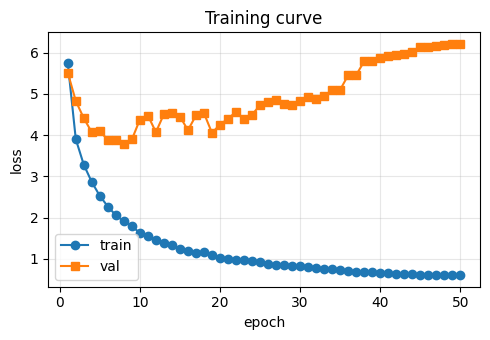

In [8]:
model = GeoSemFSP().to(DEVICE)
print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M")
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS * len(train_dl))


def to_dev(tgt):
    return {k: v.to(DEVICE, non_blocking=True) for k, v in tgt.items()}


@torch.no_grad()
def evaluate(loader, desc="eval"):
    model.eval()
    keys = ["loss", "det", "feat", "geosem", "comp", "bits", "img", "lid", "psnr", "mae_m", "u_mean", "u_std"]
    tot = {k: 0.0 for k in keys}; n_tot = 0
    d_sum, d_n = 0.0, 0.0
    for img, rv, tgt in tqdm(loader, desc=desc, leave=False):
        img, rv, tgt = img.to(DEVICE, non_blocking=True), rv.to(DEVICE, non_blocking=True), to_dev(tgt)
        out = model(img, rv)
        loss, comps = total_loss(out, img, rv, tgt, 1.0)
        b = img.size(0)
        mse = F.mse_loss(out["img"], img)
        m = rv[:, 5:6]
        mae = (torch.abs(out["range"] - rv[:, :1]) * m).sum() / (m.sum() + 1e-6) * MAX_RANGE
        vals = dict(comps, loss=loss, psnr=10 * torch.log10(1 / (mse + 1e-8)), mae_m=mae,
                    u_mean=out["U"].mean(), u_std=out["U"].std())
        for k in keys: tot[k] += vals[k].item() * b
        n_tot += b
        rm = tgt["rm"]
        d_sum += (torch.abs(out["reg"][:, 3:4] - tgt["reg"][:, 3:4]) * rm).sum().item() * MAX_RANGE
        d_n += rm.sum().item()
    res = {k: v / n_tot for k, v in tot.items()}
    res["det_dist_mae"] = d_sum / d_n if d_n > 0 else float("nan")
    return res


history = []
best_val, best_path = float("inf"), os.path.join(OUT_DIR, "geosem_fsp_best.pt")
step, total_steps = 0, EPOCHS * len(train_dl)

for epoch in range(1, EPOCHS + 1):
    model.train()
    t0, run = time.time(), 0.0
    pbar = tqdm(train_dl, desc=f"Epoch {epoch}/{EPOCHS}")
    for img, rv, tgt in pbar:
        img, rv, tgt = img.to(DEVICE, non_blocking=True), rv.to(DEVICE, non_blocking=True), to_dev(tgt)
        kl_w = KL_MAX * min(1.0, step / (0.5 * total_steps))   # annealed KL term (v3: max 0.05)
        out = model(img, rv)
        loss, c = total_loss(out, img, rv, tgt, kl_w)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        opt.step(); sched.step(); step += 1
        run += loss.item()
        pbar.set_postfix(loss=f"{loss.item():.3f}", det=f"{c['det'].item():.3f}", feat=f"{c['feat'].item():.3f}",
                         gs=f"{c['geosem'].item():.3f}", comp=f"{c['comp'].item():.3f}", bits=f"{c['bits'].item():.2f}")
    val = evaluate(val_dl, "val")
    tr_loss = run / len(train_dl)
    history.append((tr_loss, val["loss"]))
    print(f"[Epoch {epoch}] train {tr_loss:.4f} | val {val['loss']:.4f} | "
          f"val PSNR {val['psnr']:.2f} dB | val range MAE {val['mae_m']:.2f} m | "
          f"{time.time() - t0:.0f}s")
    print(f"           val terms -> L_det {val['det']:.3f} | L_feat {val['feat']:.3f} | "
          f"L_geo-sem {val['geosem']:.3f} | L_comp {val['comp']:.4f} | est. {val['bits']:.2f} bits/element")
    print(f"           U_GS mean {val['u_mean']:.3f} | std {val['u_std']:.3f}   (std near 0 = U_GS is not adapting)")
    if val["loss"] < best_val:
        best_val = val["loss"]; torch.save(model.state_dict(), best_path)

# ---- final test with best checkpoint ----
model.load_state_dict(torch.load(best_path, map_location=DEVICE))
test = evaluate(test_dl, "test")
print("\n===== TEST RESULTS =====")
print(f"total loss {test['loss']:.4f}")
print(f"  L_det {test['det']:.4f} | L_feat {test['feat']:.4f} | L_geo-sem {test['geosem']:.4f} | L_comp {test['comp']:.4f}")
print(f"  reconstruction: image L1+SSIM {test['img']:.4f} | LiDAR masked-L1+BCE {test['lid']:.4f}")
print(f"  transmission  : ~{test['bits']:.2f} bits per latent element (rate proxy; float32 = 32 bits)")
print(f"image PSNR {test['psnr']:.2f} dB | LiDAR range MAE {test['mae_m']:.2f} m")
if USE_DET:
    print(f"detection loss {test['det']:.3f} | object distance MAE at labelled centres {test['det_dist_mae']:.2f} m")

plt.figure(figsize=(5, 3.5))
plt.plot(range(1, EPOCHS + 1), [h[0] for h in history], "o-", label="train")
plt.plot(range(1, EPOCHS + 1), [h[1] for h in history], "s-", label="val")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.grid(alpha=.3); plt.title("Training curve")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "loss_curve.png"), dpi=150); plt.show()


# ============================================================================
# 5. SHOW RECONSTRUCTED IMAGE + LiDAR  (test set)
# ============================================================================

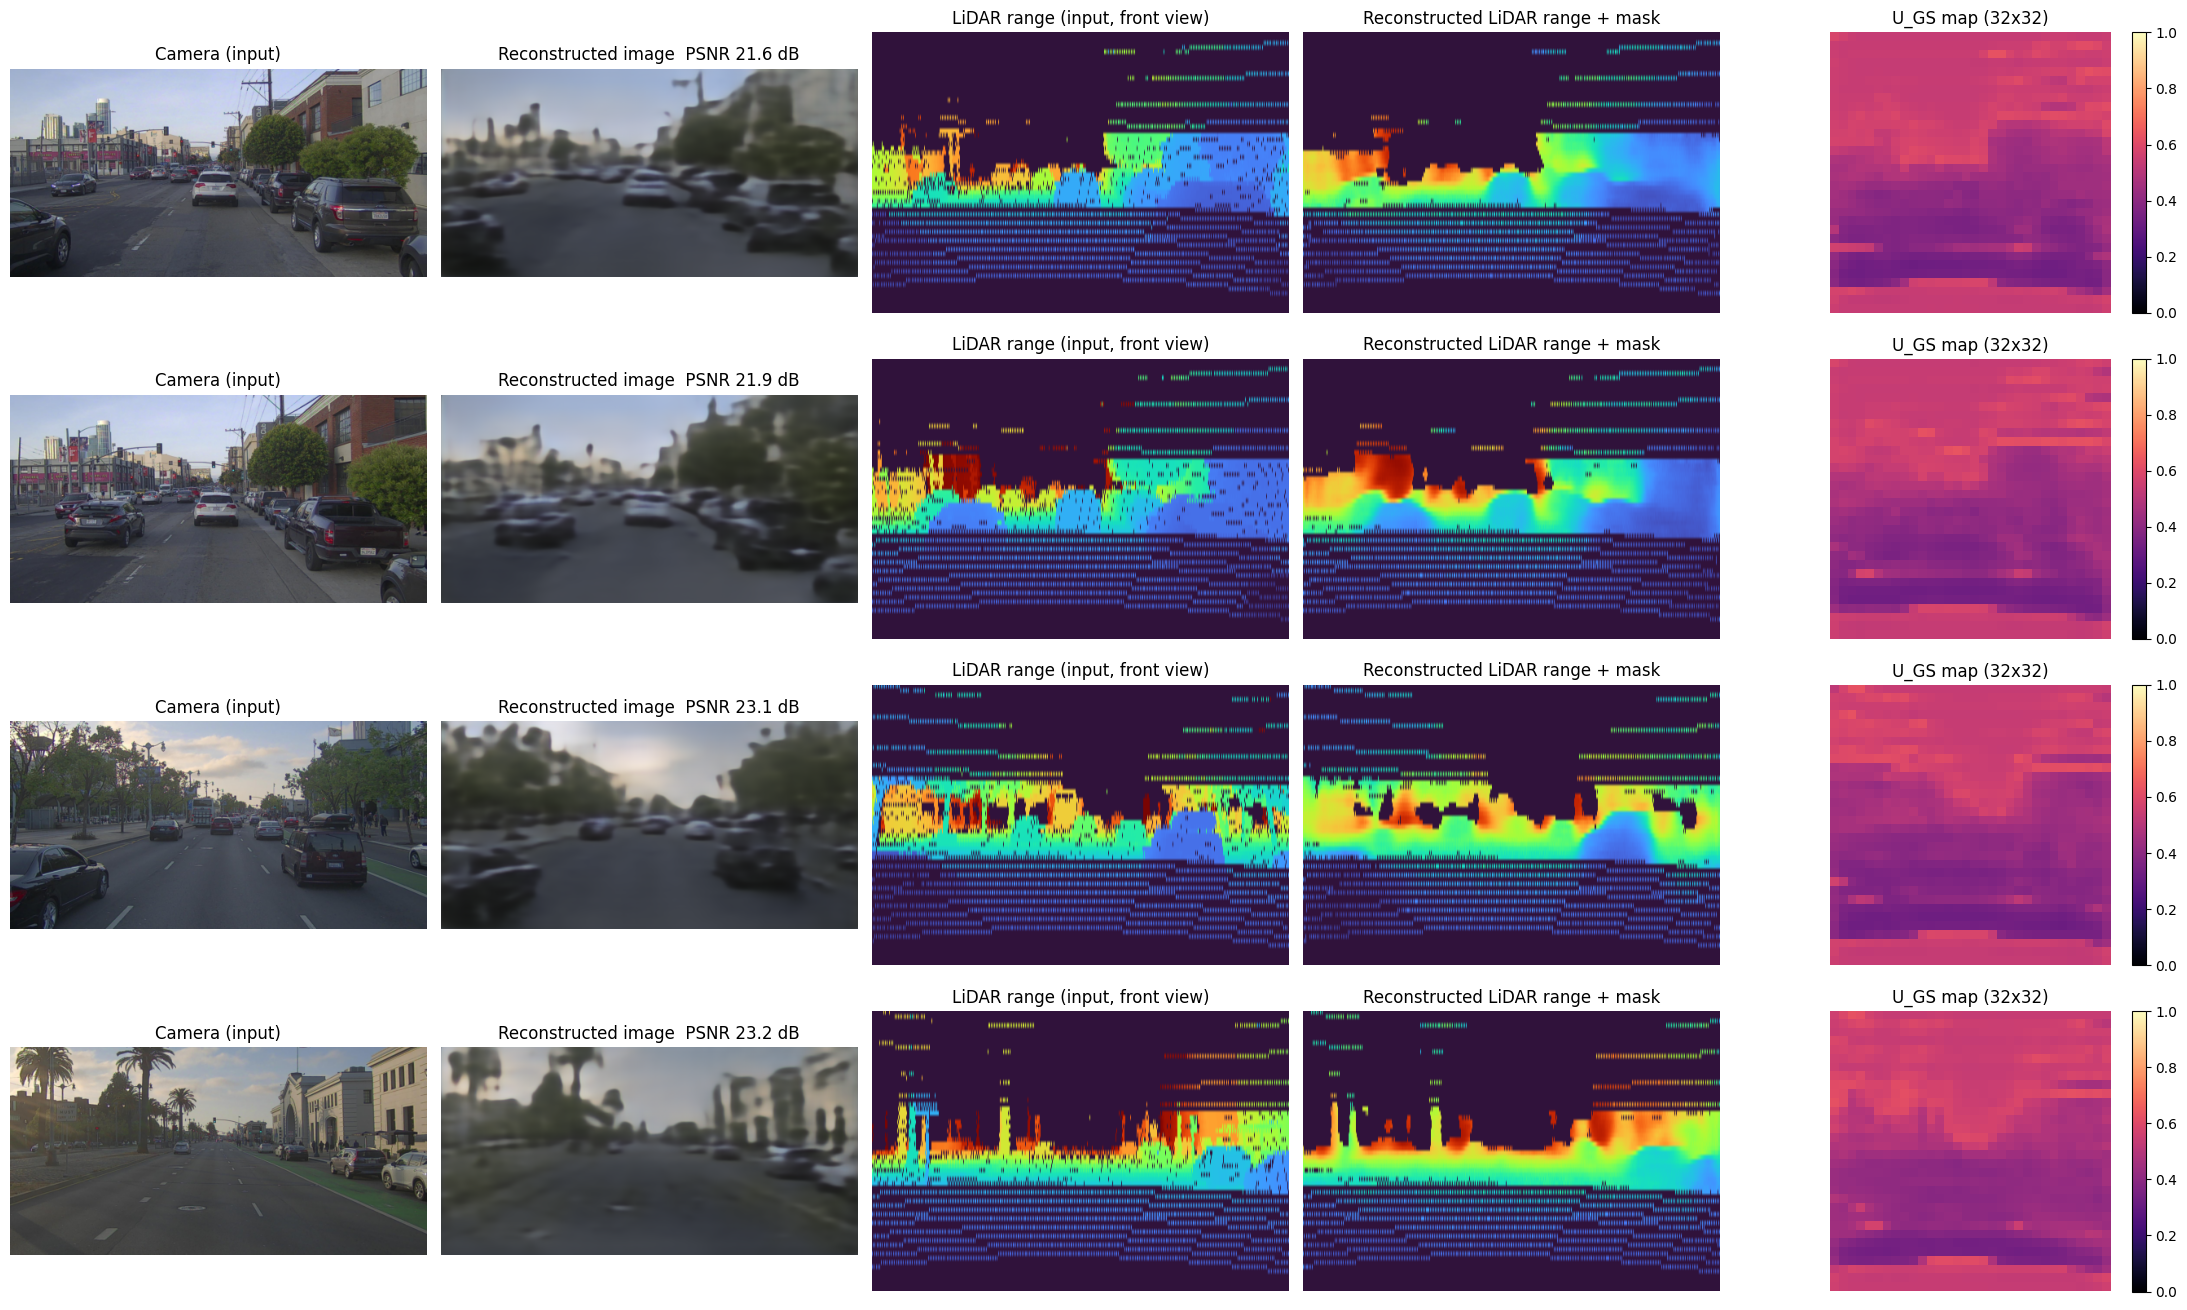

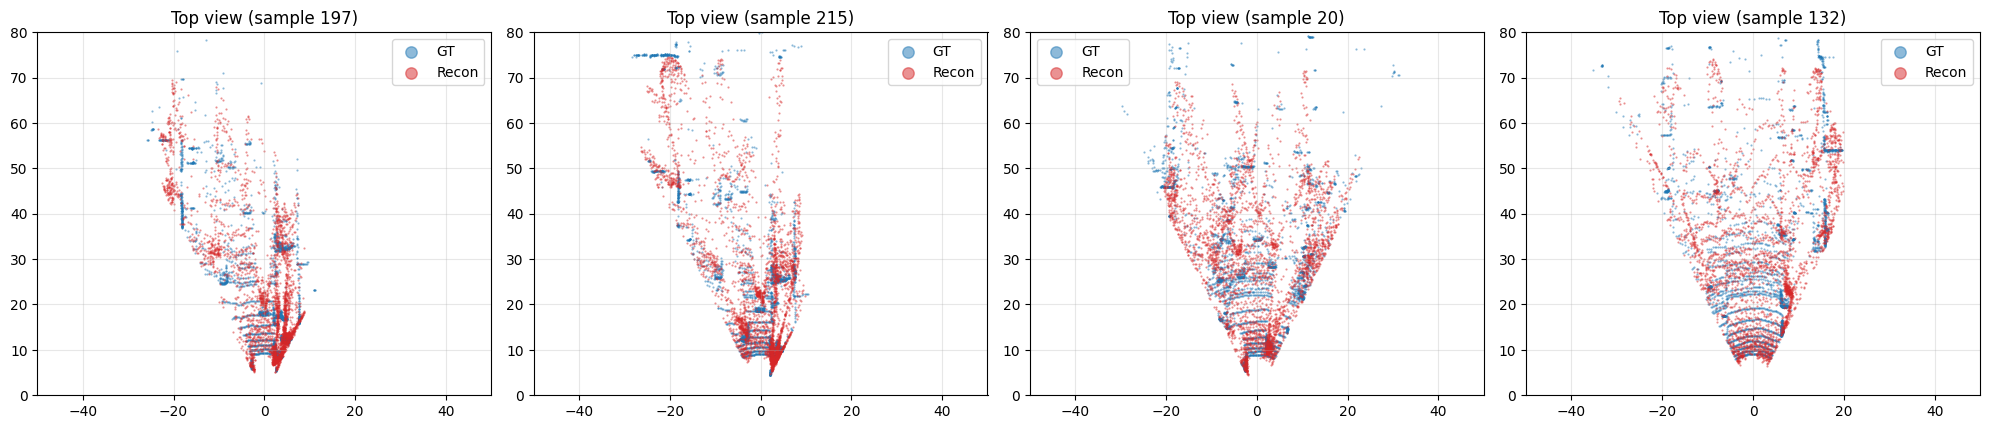

In [9]:
@torch.no_grad()
def show_results(ds, n=4, seed=0):
    model.eval()
    idxs = random.Random(seed).sample(range(len(ds)), min(n, len(ds)))
    fig, axs = plt.subplots(len(idxs), 5, figsize=(22, 3.3 * len(idxs)))
    axs = np.atleast_2d(axs)
    fig2, axs2 = plt.subplots(1, len(idxs), figsize=(5 * len(idxs), 5)); axs2 = np.atleast_1d(axs2)

    for r, i in enumerate(idxs):
        img, rv, _ = ds[i]
        out = model(img[None].to(DEVICE), rv[None].to(DEVICE))
        rec_img = out["img"][0].permute(1, 2, 0).cpu().numpy()
        gt_img = img.permute(1, 2, 0).numpy()
        gt_r = rv[0].numpy() * MAX_RANGE * rv[5].numpy()
        pm = torch.sigmoid(out["mask_logit"])[0, 0].cpu().numpy() > 0.5
        rec_r = out["range"][0, 0].cpu().numpy() * MAX_RANGE * pm
        U = out["U"][0, 0].cpu().numpy()
        psnr = 10 * np.log10(1 / (np.mean((rec_img - gt_img) ** 2) + 1e-8))

        axs[r, 0].imshow(gt_img);  axs[r, 0].set_title("Camera (input)")
        axs[r, 1].imshow(np.clip(rec_img, 0, 1)); axs[r, 1].set_title(f"Reconstructed image  PSNR {psnr:.1f} dB")
        axs[r, 2].imshow(gt_r, cmap="turbo", vmin=0, vmax=MAX_RANGE, aspect="auto"); axs[r, 2].set_title("LiDAR range (input, front view)")
        axs[r, 3].imshow(rec_r, cmap="turbo", vmin=0, vmax=MAX_RANGE, aspect="auto"); axs[r, 3].set_title("Reconstructed LiDAR range + mask")
        im = axs[r, 4].imshow(U, cmap="magma", vmin=0, vmax=1); axs[r, 4].set_title("U_GS map (32x32)")
        plt.colorbar(im, ax=axs[r, 4], fraction=0.046)
        for a in axs[r]: a.axis("off")

        # top-down view of the point cloud rebuilt from the range image (rays from the intrinsics)
        fx, fy, cx0, cy0 = ds.samples[i]["K"]
        uu = ((np.arange(RV_W) + 0.5) / RV_W * ORIG_W - cx0) / fx
        vv = ((np.arange(RV_H) + 0.5) / RV_H * ORIG_H - cy0) / fy
        nrm = np.sqrt(uu[None, :] ** 2 + vv[:, None] ** 2 + 1.0)
        for (rr, c, name) in ((gt_r, "tab:blue", "GT"), (rec_r, "tab:red", "Recon")):
            v = rr > 0
            X, Z = rr * uu[None, :] / nrm, rr / nrm
            axs2[r].scatter(X[v][::3], Z[v][::3], s=0.3, c=c, alpha=0.5, label=name)
        axs2[r].set_aspect("equal"); axs2[r].set_xlim(-50, 50); axs2[r].set_ylim(0, 80)
        axs2[r].set_title(f"Top view (sample {i})"); axs2[r].legend(markerscale=15); axs2[r].grid(alpha=.3)

    fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "reconstructions.png"), dpi=130)
    fig2.tight_layout(); fig2.savefig(os.path.join(OUT_DIR, "lidar_topview.png"), dpi=130)
    plt.show()


show_results(test_ds, n=4)


# ============================================================================
# 6. SCENE REPORT AFTER FUSION : what objects, how many, how far
# ============================================================================


SCENE REPORT  (test frame 68)
Detected objects : 6 Car, 6 Pedestrian, 1 Bus
Ground-truth     : 7 Car, 2 Bus, 28 Pedestrian, 5 TwoWheeler
Total detected   : 13
 # class        conf  dist(final)  dist(pred)  dist(LiDAR)  lateral  direction reliab.
 1 Car          0.37        5.3 m      12.3 m        5.3 m   +4.7 m  right      0.62
 2 Car          0.83       15.9 m      20.2 m       15.9 m   -1.7 m  ahead      0.64
 3 Car          0.86       26.0 m      32.2 m       26.0 m   +6.2 m  right      0.56
 4 Pedestrian   0.38       27.4 m      65.1 m       27.4 m  -16.0 m  left       0.53
 5 Pedestrian   0.77       27.8 m      59.8 m       27.8 m  +12.7 m  right      0.53
 6 Pedestrian   0.72       28.3 m      44.1 m       28.3 m  +15.4 m  right      0.55
 7 Car          0.88       30.1 m      34.8 m       30.1 m   +0.8 m  ahead      0.57
 8 Pedestrian   0.60       32.7 m      33.9 m       32.7 m  +14.4 m  right      0.56
 9 Pedestrian   0.35       33.5 m      32.2 m       33.5 m  +12.8 m  righ

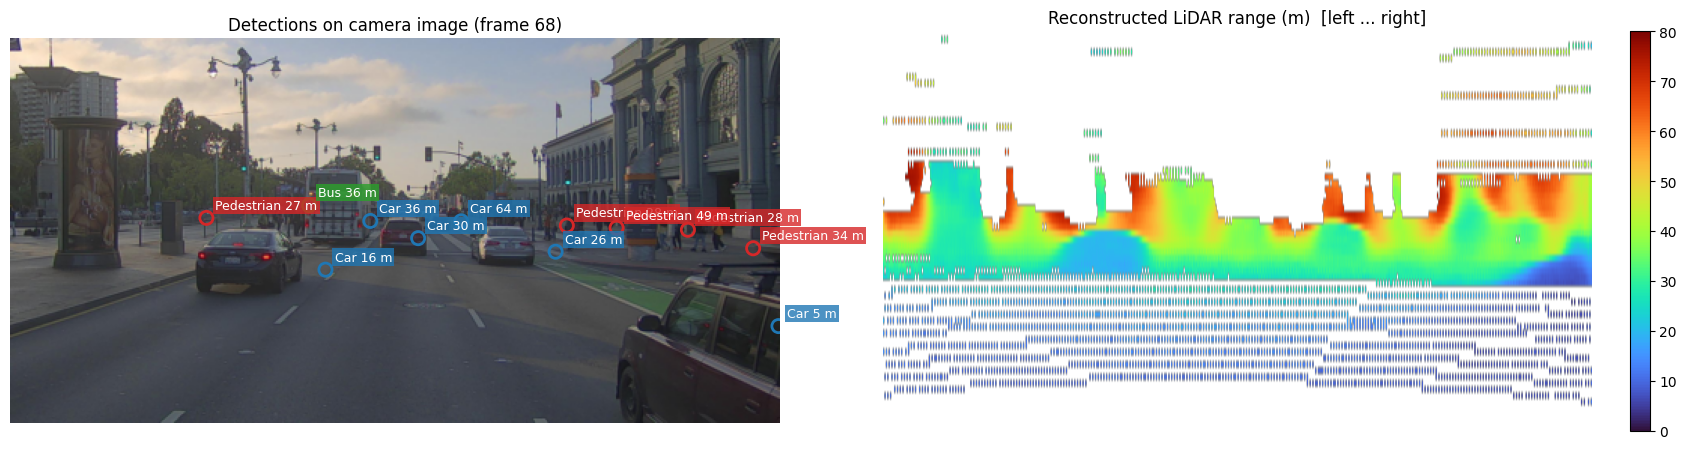


SCENE REPORT  (test frame 291)
Detected objects : 6 Car, 5 Pedestrian
Ground-truth     : 9 Car, 17 Pedestrian
Total detected   : 11
 # class        conf  dist(final)  dist(pred)  dist(LiDAR)  lateral  direction reliab.
 1 Car          0.72       12.5 m      17.8 m       12.5 m   +3.2 m  right      0.59
 2 Car          0.50       12.5 m      13.2 m       12.5 m   +3.2 m  right      0.57
 3 Pedestrian   0.68       37.4 m      58.3 m       37.4 m  +19.5 m  right      0.45
 4 Car          0.73       41.4 m      50.1 m       41.4 m   +5.9 m  ahead      0.53
 5 Car          0.94       46.3 m      58.8 m       46.3 m   +0.8 m  ahead      0.52
 6 Pedestrian   0.81       46.8 m      60.1 m       46.8 m  +15.9 m  right      0.51
 7 Pedestrian   0.78       54.1 m      60.6 m       54.1 m  +17.0 m  right      0.50
 8 Pedestrian   0.38       56.1 m      55.9 m       56.1 m  +20.7 m  right      0.49
 9 Car          0.91       57.5 m      61.3 m       57.5 m   +4.2 m  ahead      0.52
10 Pedestrian  

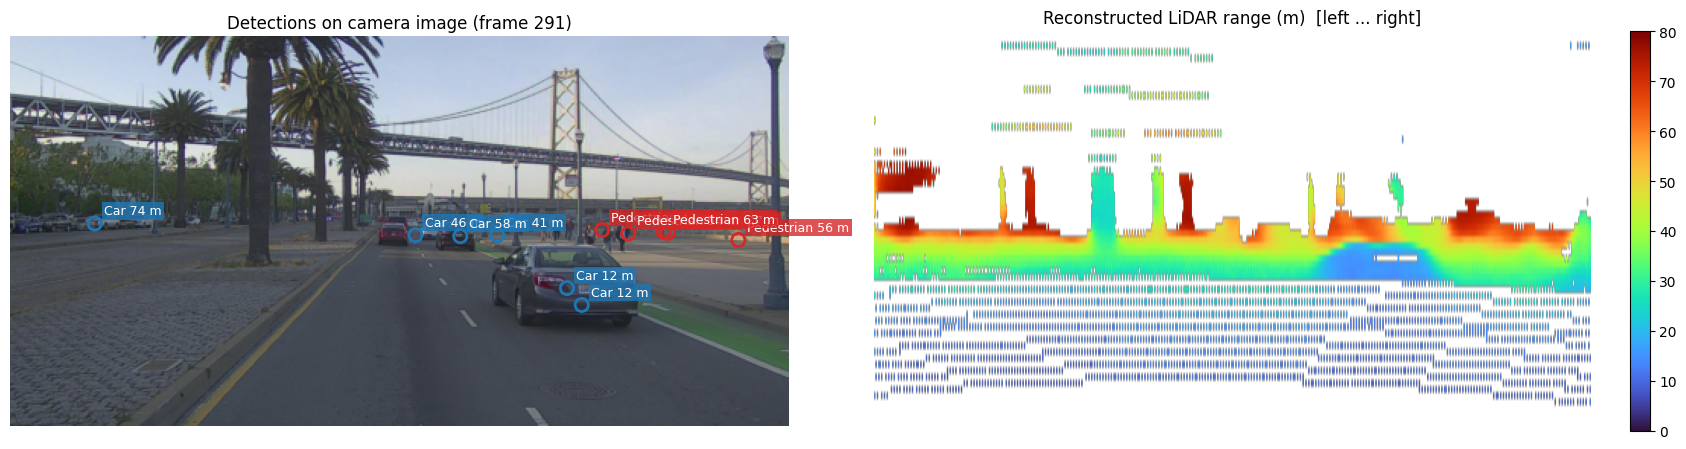


SCENE REPORT  (test frame 32)
Detected objects : 10 Car, 7 Pedestrian, 1 Bus
Ground-truth     : 10 Car, 1 Bus, 38 Pedestrian, 1 TwoWheeler, 1 Obstacle
Total detected   : 18
 # class        conf  dist(final)  dist(pred)  dist(LiDAR)  lateral  direction reliab.
 1 Car          0.43        8.6 m      17.9 m        8.6 m   +4.1 m  right      0.63
 2 Car          0.52        8.7 m      11.7 m        8.7 m   +2.8 m  right      0.65
 3 Pedestrian   0.66        8.9 m      28.1 m        8.9 m  +10.1 m  right      0.58
 4 Car          0.41        9.0 m      24.3 m        9.0 m   +6.4 m  right      0.60
 5 Car          0.54       10.1 m      46.9 m       10.1 m  +13.4 m  right      0.55
 6 Pedestrian   0.32       18.8 m      35.8 m       18.8 m  +16.6 m  right      0.54
 7 Pedestrian   0.54       22.2 m      69.6 m       22.2 m  -19.7 m  left       0.53
 8 Car          0.88       22.7 m      29.4 m       22.7 m   -2.4 m  ahead      0.59
 9 Car          0.89       26.7 m      34.1 m       26.7 m 

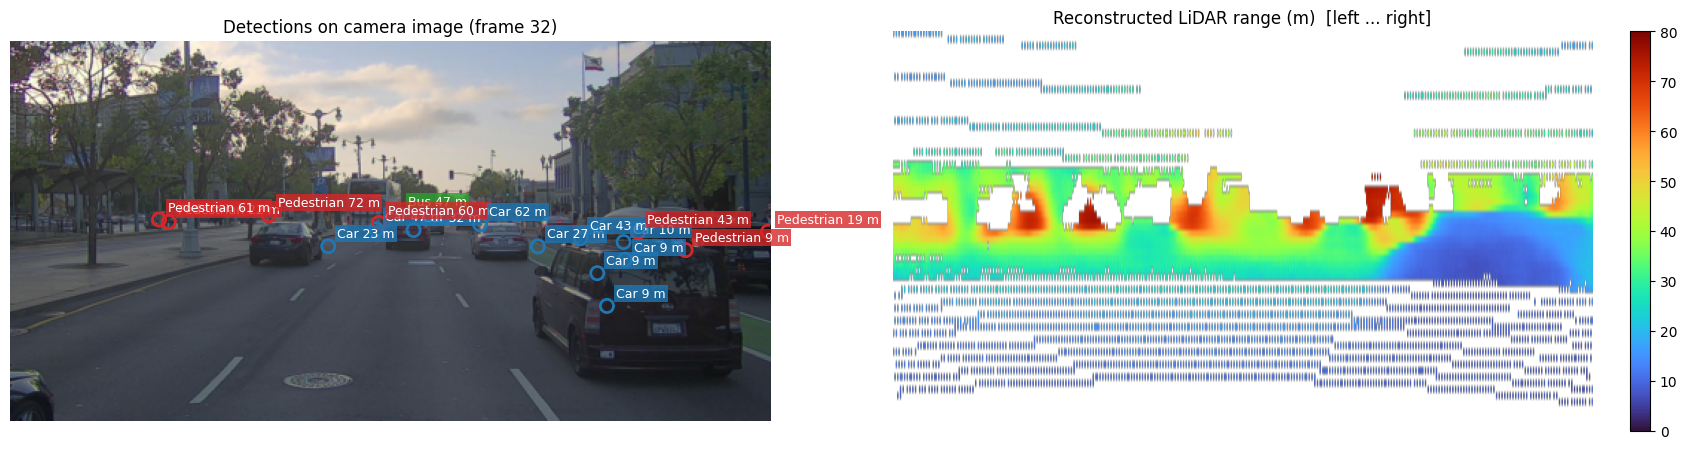


Saved scene_reports.json and scene_report_*.png in /kaggle/working


In [10]:
def zone_distances(rec_range_m, rec_mask, K):
    """Nearest reconstructed LiDAR return in left / centre / right third of the image, in a band
       around the horizon (-4..+8 deg elevation, found with the intrinsics) to mostly skip road."""
    fx, fy, cx, cy = K
    v_hi = cy - fy * math.tan(math.radians(8.0))
    v_lo = cy - fy * math.tan(math.radians(-4.0))
    r0 = int(np.clip(v_hi / ORIG_H * RV_H, 0, RV_H - 2))
    r1 = int(np.clip(v_lo / ORIG_H * RV_H, r0 + 1, RV_H))
    out = {}
    for name, (c0, c1) in dict(left=(0, RV_W // 3), centre=(RV_W // 3, 2 * RV_W // 3), right=(2 * RV_W // 3, RV_W)).items():
        band = rec_range_m[r0:r1, c0:c1]; ok = rec_mask[r0:r1, c0:c1] > 0
        out[name] = float(band[ok].min()) if ok.sum() > 5 else None
    return out


@torch.no_grad()
def decode_objects(out, rv_t, thr=DET_THR, topk=40):
    """Heatmap peaks -> list of objects (ONE class per location, per-class thresholds).
       dist_pred_m : distance regressed by the network (from the compressed latent only)
       dist_lidar_m: nearest LiDAR surface in the same direction (vehicle-side measurement)
       dist_m      : distance used in the report = LiDAR value if available, else the prediction"""
    hm = torch.sigmoid(out["hm_logit"][0])                                    # (N_DET, DET_H, DET_W)
    score_map, cls_map = hm.max(0)                                            # best class per location
    keep = (F.max_pool2d(score_map[None, None], 3, 1, 1)[0, 0] == score_map).float()
    scores, inds = (keep * score_map).flatten().topk(topk)
    cls_flat = cls_map.flatten()
    rv = rv_t.numpy()
    rs, cs = RV_H // DET_H, RV_W // DET_W                                     # range-image pixels per detection cell
    objs = []
    for s_, ind in zip(scores.tolist(), inds.tolist()):
        if s_ < thr: break
        c = int(cls_flat[ind]); y, x = divmod(ind, DET_W)
        if s_ < DET_THR_CLS[DET_CLASSES[c]]: continue
        r = out["reg"][0, :, y, x].cpu().numpy()
        X, Y, Z, D = float(r[0] * 40), float(r[1] * 10), float(r[2] * 80), float(r[3] * 80)
        az = math.degrees(math.atan2(X, max(Z, 1e-3)))     # direction from predicted x, z
        # LiDAR measurement around the cell (25th percentile = nearest surface)
        rr = slice(max(0, (y - 1) * rs), (y + 2) * rs)
        cc = slice(max(0, x * cs - cs // 2), (x + 1) * cs + cs // 2)
        vals = rv[0, rr, cc][rv[5, rr, cc] > 0]
        lid_d = float(np.percentile(vals, 25) * MAX_RANGE) if vals.size >= 3 else None
        unc = float(out["U"][0, 0, y * GRID // DET_H, x * GRID // DET_W])        # U_GS lives on the 32x32 grid
        objs.append(dict(cls=DET_CLASSES[c], score=round(s_, 3), x_m=round(X, 1), y_m=round(Y, 1), z_m=round(Z, 1),
                         dist_pred_m=round(D, 1), dist_lidar_m=None if lid_d is None else round(lid_d, 1),
                         dist_m=round(lid_d if lid_d is not None else D, 1),
                         azimuth_deg=round(az, 1),
                         direction="left" if az < -8 else "right" if az > 8 else "ahead",
                         reliability=round(1 - unc, 2)))
    return sorted(objs, key=lambda o: o["dist_m"])


@torch.no_grad()
def scene_report(ds, n=3, seed=1):
    model.eval()
    idxs = random.Random(seed).sample(range(len(ds)), min(n, len(ds)))
    all_reports = []
    cmap = plt.get_cmap("tab10")
    for i in idxs:
        img, rv, tgt = ds[i]
        out = model(img[None].to(DEVICE), rv[None].to(DEVICE))
        out = {k: v.float() for k, v in out.items()}
        pm = (torch.sigmoid(out["mask_logit"])[0, 0].cpu().numpy() > 0.5)
        rec_r = out["range"][0, 0].cpu().numpy() * MAX_RANGE
        zones = zone_distances(rec_r, pm.astype(np.float32), ds.samples[i]["K"])
        objs = decode_objects(out, rv) if USE_DET else []
        gt_cnt = {DET_CLASSES[c]: int(tgt["hm"][c].eq(1).sum()) for c in range(N_DET)} if USE_DET else {}

        counts = {}
        for o in objs: counts[o["cls"]] = counts.get(o["cls"], 0) + 1
        print("\n" + "=" * 78)
        print(f"SCENE REPORT  (test frame {i})")
        if USE_DET:
            print("Detected objects :", ", ".join(f"{v} {k}" for k, v in counts.items()) or "none above threshold")
            print("Ground-truth     :", ", ".join(f"{v} {k}" for k, v in gt_cnt.items() if v) or "none")
            print(f"Total detected   : {len(objs)}")
            if objs:
                print(f"{'#':>2} {'class':<11}{'conf':>6}{'dist(final)':>13}{'dist(pred)':>12}{'dist(LiDAR)':>13}{'lateral':>9}  {'direction':<7}{'reliab.':>8}")
                for k, o in enumerate(objs, 1):
                    ld_ = "-" if o["dist_lidar_m"] is None else f"{o['dist_lidar_m']:.1f} m"
                    print(f"{k:>2} {o['cls']:<11}{o['score']:>6.2f}{o['dist_m']:>11.1f} m{o['dist_pred_m']:>10.1f} m{ld_:>13}"
                          f"{o['x_m']:>+7.1f} m  {o['direction']:<7}{o['reliability']:>8.2f}")
                print("   dist(final) = LiDAR distance when available, otherwise the network prediction")
        fmt = lambda v: "no return" if v is None else f"{v:.1f} m"
        print(f"Nearest LiDAR return  left: {fmt(zones['left'])} | centre: {fmt(zones['centre'])} | right: {fmt(zones['right'])}")
        if USE_DET and objs:
            near = objs[0]
            print(f"Closest object: {near['cls']} about {near['dist_m']:.1f} m {near['direction']}.")

        # ---- picture: image with labelled detections + range map ----
        fig, ax = plt.subplots(1, 2, figsize=(17, 4.6))
        ax[0].imshow(img.permute(1, 2, 0).numpy()); ax[0].set_title(f"Detections on camera image (frame {i})")
        fx, fy, cx0, cy0 = test_ds.samples[i]["K"]
        for o in objs:
            if o["z_m"] <= 1: continue
            u = (fx * o["x_m"] / o["z_m"] + cx0) * IMG_W / ORIG_W
            v = (fy * o["y_m"] / o["z_m"] + cy0) * IMG_H / ORIG_H
            if 0 <= u < IMG_W and 0 <= v < IMG_H:
                col = cmap(DET_CLASSES.index(o["cls"]))
                ax[0].scatter([u], [v], s=90, facecolors="none", edgecolors=col, linewidths=2)
                ax[0].text(u + 6, v - 6, f"{o['cls']} {o['dist_m']:.0f} m", color="white", fontsize=9,
                           bbox=dict(facecolor=col, alpha=0.8, pad=1.5, edgecolor="none"))
        ax[0].axis("off")
        rr_ = np.where(pm, rec_r, np.nan)
        im = ax[1].imshow(rr_, cmap="turbo", vmin=0, vmax=MAX_RANGE, aspect="auto")
        ax[1].set_title("Reconstructed LiDAR range (m)  [left ... right]"); plt.colorbar(im, ax=ax[1], fraction=0.03)
        ax[1].axis("off")
        plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f"scene_report_{i}.png"), dpi=130); plt.show()
        all_reports.append(dict(frame=i, counts=counts, ground_truth=gt_cnt, zones=zones, objects=objs))

    with open(os.path.join(OUT_DIR, "scene_reports.json"), "w") as f:
        json.dump(all_reports, f, indent=2)
    print("\nSaved scene_reports.json and scene_report_*.png in", OUT_DIR)


scene_report(test_ds, n=3)


# ============================================================================
# 7. YOLO + LiDAR : what is it (YOLO), how far (LiDAR points inside the box)
# ============================================================================

In [ ]:
def load_cam_points(lidar_path, w2c):
    """All LiDAR points of the frame in camera coordinates (x right, y down, z forward)."""
    df = pd.read_pickle(lidar_path)
    pts = df[["x", "y", "z"]].to_numpy(np.float64)
    pc = pts @ w2c[:3, :3].T + w2c[:3, 3]
    return pc[pc[:, 2] > 0.5]


def box_distance(pc, K, box, shrink=0.2, max_d=100.0):
    """Distance / position of a 2D box from the LiDAR points projected inside its centre.
       Uses the nearest half of those points so the background behind the object is ignored."""
    fx, fy, cx, cy = K
    x1, y1, x2, y2 = box
    w, h = x2 - x1, y2 - y1
    u = fx * pc[:, 0] / pc[:, 2] + cx
    v = fy * pc[:, 1] / pc[:, 2] + cy
    m = (u >= x1 + shrink * w) & (u <= x2 - shrink * w) & (v >= y1 + shrink * h) & (v <= y2 - shrink * h)
    sel = pc[m]
    if len(sel) < 3:
        return None
    d = np.linalg.norm(sel, axis=1)
    near = sel[d <= np.median(d)]
    dn = np.linalg.norm(near, axis=1)
    X, Z = float(np.median(near[:, 0])), float(np.median(near[:, 2]))
    az = math.degrees(math.atan2(X, Z))
    if np.linalg.norm(near.mean(0)) > max_d:
        return None
    return dict(dist_m=float(np.median(dn)), x_m=X, z_m=Z, azimuth_deg=az, n_points=int(len(sel)))


@torch.no_grad()
def yolo_lidar_report(ds, n=3, seed=1):
    try:
        try:
            from ultralytics import YOLO
        except ImportError:
            import subprocess, sys
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
            from ultralytics import YOLO
        yolo = YOLO(YOLO_WEIGHTS)
    except Exception as e:
        print("\n[YOLO] Could not load YOLO (turn Internet ON in Kaggle settings, or set YOLO_WEIGHTS "
              f"to a .pt file in /kaggle/input). Reason: {e}")
        return

    model.eval()
    idxs = random.Random(seed).sample(range(len(ds)), min(n, len(ds)))
    cmap = plt.get_cmap("tab10")
    reports = []
    for i in idxs:
        smp = ds.samples[i]
        res = yolo.predict(smp["img"], conf=YOLO_CONF, classes=YOLO_CLASSES, verbose=False)[0]
        names = res.names
        pc = load_cam_points(smp["lid"], smp["w2c"])

        # fusion-head detections for the same frame (to cross-check)
        head_objs = []
        if USE_DET:
            img_t, rv_t, _ = ds[i]
            out = model(img_t[None].to(DEVICE), rv_t[None].to(DEVICE))
            head_objs = decode_objects({k: v.float() for k, v in out.items()}, rv_t)

        objs = []
        for b, c, k in zip(res.boxes.xyxy.cpu().numpy(), res.boxes.conf.cpu().numpy(), res.boxes.cls.cpu().numpy()):
            name = names[int(k)]
            info = box_distance(pc, smp["K"], b)
            o = dict(cls=name, conf=round(float(c), 2), box=[round(float(v)) for v in b],
                     dist_m=None if info is None else round(info["dist_m"], 1),
                     lateral_m=None if info is None else round(info["x_m"], 1),
                     azimuth_deg=None if info is None else round(info["azimuth_deg"], 1),
                     lidar_points=0 if info is None else info["n_points"], fusion_head="n/a")
            if info is not None:
                o["direction"] = "left" if info["azimuth_deg"] < -8 else "right" if info["azimuth_deg"] > 8 else "ahead"
                grp = YOLO_TO_DET.get(name)
                if USE_DET and grp is not None:
                    ok = any(h["cls"] == grp and abs(h["dist_m"] - info["dist_m"]) <= 5.0
                             and abs(h["azimuth_deg"] - info["azimuth_deg"]) <= 6.0 for h in head_objs)
                    o["fusion_head"] = "agree" if ok else "no match"
            else:
                o["direction"] = "-"
            objs.append(o)
        objs.sort(key=lambda o: (o["dist_m"] is None, o["dist_m"] or 0))

        counts = {}
        for o in objs: counts[o["cls"]] = counts.get(o["cls"], 0) + 1
        print("\n" + "=" * 86)
        print(f"YOLO + LiDAR REPORT  (test frame {i})")
        print("YOLO objects :", ", ".join(f"{v} {k}" for k, v in counts.items()) or "none")
        print(f"Total        : {len(objs)}")
        if objs:
            print(f"{'#':>2} {'class':<14}{'conf':>5}{'distance':>10}{'lateral':>9}  {'dir':<6}{'LiDAR pts':>10}  fusion-head")
            for k, o in enumerate(objs, 1):
                dd = "no LiDAR" if o["dist_m"] is None else f"{o['dist_m']:.1f} m"
                ll_ = "-" if o["lateral_m"] is None else f"{o['lateral_m']:+.1f} m"
                print(f"{k:>2} {o['cls']:<14}{o['conf']:>5.2f}{dd:>10}{ll_:>9}  {o['direction']:<6}{o['lidar_points']:>10}  {o['fusion_head']}")
            near = next((o for o in objs if o["dist_m"] is not None), None)
            if near:
                print(f"Closest      : {near['cls']} at {near['dist_m']:.1f} m ({near['direction']})")

        im = Image.open(smp["img"]).convert("RGB")
        fig, ax = plt.subplots(figsize=(14, 8)); ax.imshow(im); ax.axis("off")
        ax.set_title(f"YOLO + LiDAR distance (frame {i})")
        for o in objs:
            x1, y1, x2, y2 = o["box"]
            col = cmap(hash(o["cls"]) % 10)
            ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=col, linewidth=2.5))
            lab = o["cls"] + ("" if o["dist_m"] is None else f" {o['dist_m']:.0f} m")
            ax.text(x1, max(y1 - 6, 0), lab, color="white", fontsize=11,
                    bbox=dict(facecolor=col, alpha=0.85, pad=2, edgecolor="none"))
        plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f"yolo_lidar_{i}.png"), dpi=110); plt.show()
        reports.append(dict(frame=i, counts=counts, objects=objs))

    with open(os.path.join(OUT_DIR, "yolo_lidar_reports.json"), "w") as f:
        json.dump(reports, f, indent=2)
    print("\nSaved yolo_lidar_reports.json and yolo_lidar_*.png in", OUT_DIR)


if USE_YOLO:
    yolo_lidar_report(test_ds, n=3)

print("Saved: geosem_fsp_best.pt, loss_curve.png, reconstructions.png, lidar_topview.png in", OUT_DIR)